In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# For regression modeling
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Display plots in the notebook
%matplotlib inline

Load Dataset

In [3]:
data_path="data/medical_insurance.csv"

In [4]:
df=pd.read_csv(data_path)

In [5]:
# show first 5 rows
df.head()

,age,gender,bmi,children,discount_eligibility,region,expenses,premium
0,19,female,27.9,0,yes,southwest,16884.92,168.8492
1,18,male,33.8,1,no,southeast,1725.55,17.2555
2,28,male,33.0,3,no,southeast,4449.46,44.4946
3,33,male,22.7,0,no,northwest,21984.47,439.6894
4,32,male,28.9,0,no,northwest,3866.86,77.3372


In [6]:
# overview of dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   1338 non-null   int64  
 1   gender                1338 non-null   object 
 2   bmi                   1338 non-null   float64
 3   children              1338 non-null   int64  
 4   discount_eligibility  1338 non-null   object 
 5   region                1338 non-null   object 
 6   expenses              1338 non-null   float64
 7   premium               1338 non-null   float64
dtypes: float64(3), int64(2), object(3)
memory usage: 83.8+ KB


In [7]:
# check for missing values
df.isnull().sum()

age                     0
gender                  0
bmi                     0
children                0
discount_eligibility    0
region                  0
expenses                0
premium                 0
dtype: int64

In [8]:
# statistical summary
df.describe()

,age,bmi,children,expenses,premium
count,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.665471,1.094918,13270.422414,262.874685
std,14.049960,6.098382,1.205493,12110.011240,292.532178
min,18.000000,16.000000,0.000000,1121.870000,11.218700
25%,27.000000,26.300000,0.000000,4740.287500,87.354250
50%,39.000000,30.400000,1.000000,9382.030000,174.997400
75%,51.000000,34.700000,2.000000,16639.915000,342.908900
max,64.000000,53.100000,5.000000,63770.430000,1983.106400


EDA

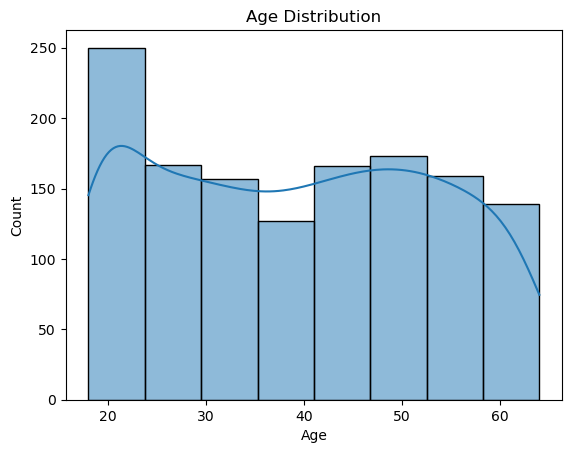

In [9]:
# Age Distribution
sns.histplot(df['age'], bins=8, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

To obtain a clearer overview of the age distribution, we selected a smaller number of bins. The majority of policyholders are between 18 and 23 years old, while the next largest group falls within the 40 to 60 years range.

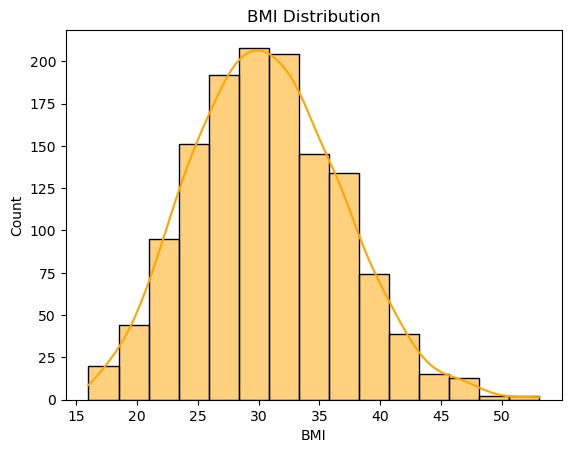

In [10]:
# BMI Distribution
sns.histplot(df['bmi'], bins=15, kde=True, color='orange')
plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Count")
plt.show()

This plot shows that BMI follows an approximately normal distribution, centered around an average of 30 and ranging from 16 to 53.

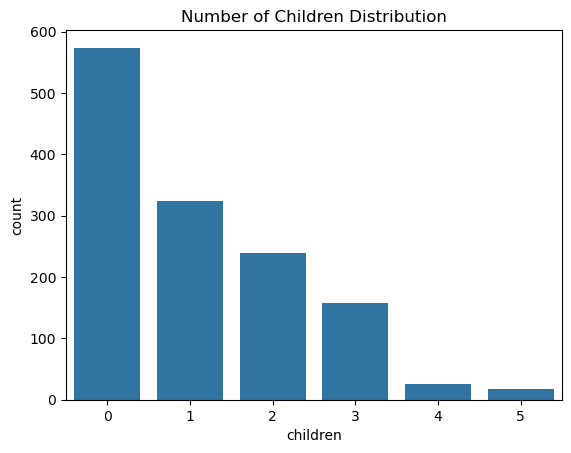

In [11]:
# Children
sns.countplot(x='children', data=df)
plt.title("Number of Children Distribution")
plt.show()

Most of policyholders has no child.

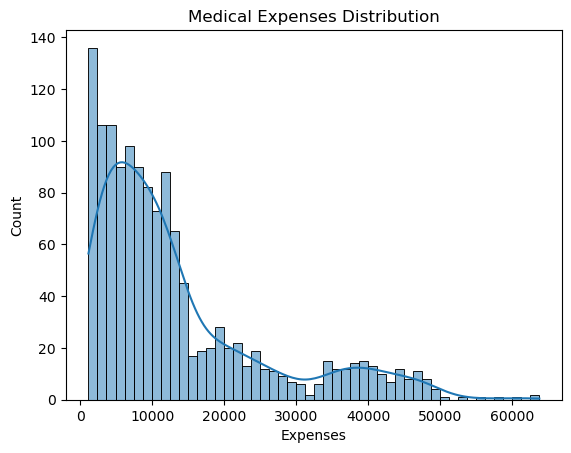

In [12]:
# Expense
sns.histplot(df['expenses'], bins=50, kde=True)
plt.title("Medical Expenses Distribution")
plt.xlabel("Expenses")
plt.ylabel("Count")
plt.show()

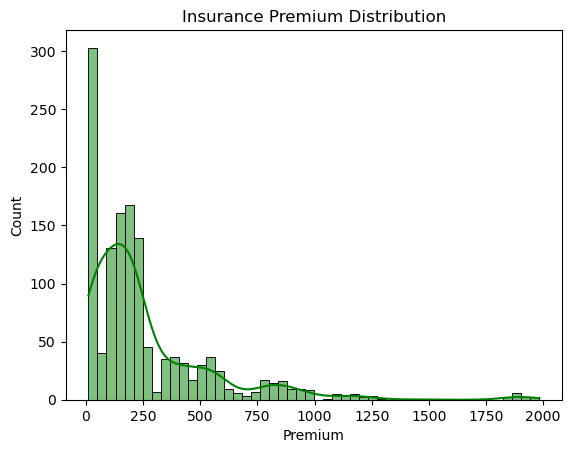

In [13]:
# Premium
sns.histplot(df['premium'], bins=50, kde=True, color='green')
plt.title("Insurance Premium Distribution")
plt.xlabel("Premium")
plt.ylabel("Count")
plt.show()

The distributions of expenses and premium are both skewed.

The expenses distribution shows a general decreasing trend from the first bin up to around 15,000, with two notable peaks near 20,000 and 40,000.

The premium distribution has the highest frequency in the first bin, followed by three distinct clusters at higher premium ranges.

These observations suggest that while most policyholders have lower expenses and premiums, there are smaller groups with significantly higher values, which may need special consideration in modeling.

Categorical Feature Analysis

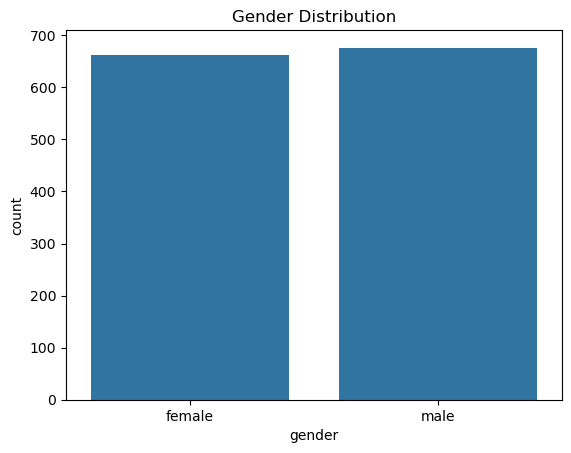

In [14]:
sns.countplot(x='gender', data=df)
plt.title("Gender Distribution")
plt.show()

The distribution of policyholders’ genders is nearly balanced

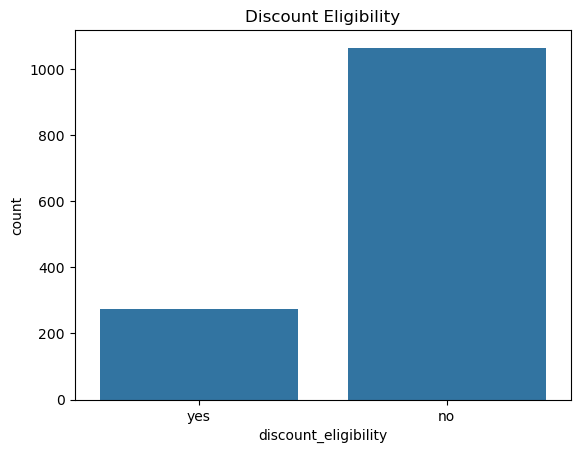

In [15]:
# discount aligibility
sns.countplot(x='discount_eligibility', data=df)
plt.title("Discount Eligibility")
plt.show()

For discount eligibility, over 1,000 policyholders are not eligible, while fewer than 300 are eligible.

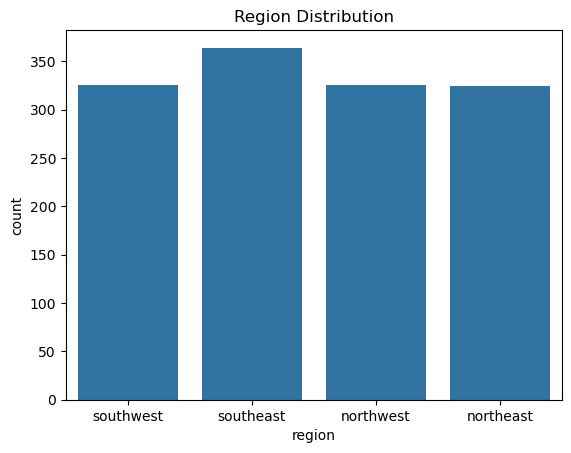

In [16]:
# Region
sns.countplot(x='region', data=df)
plt.title("Region Distribution")
plt.show()

The policyholders are distributed fairly evenly across the four regions, with southeast having a slightly higher count of around 300.

Pairwise Correlations

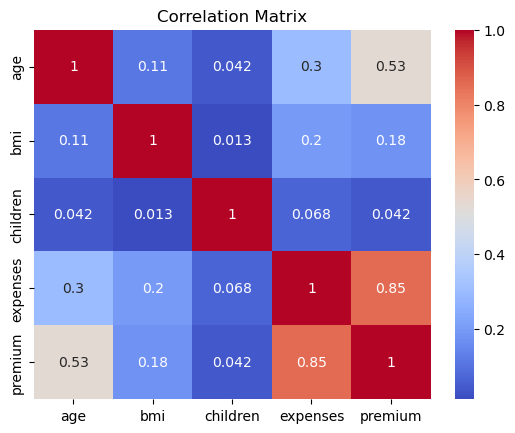

In [17]:
numeric_cols = ['age','bmi','children','expenses','premium']
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

The correlation matrix reveals the following relationships between numeric features:

Expenses and Premium: Strong positive correlation (0.85), indicating that higher expenses are closely associated with higher premiums.

Premium and Age: Moderate positive correlation (0.53), suggesting that older policyholders tend to pay higher premiums.

Expenses and Age: Weak positive correlation (0.30), showing a slight tendency for expenses to increase with age.

Expenses and BMI: Weak positive correlation (0.20), indicating a minor effect of BMI on expenses.

Premium and BMI: Weak positive correlation (0.18), suggesting BMI has limited influence on premiums.

These correlations indicate that premium is most strongly linked to expenses, while age and BMI play smaller roles in determining insurance costs.

The correlation analysis indicates that expenses is the strongest predictor of premium, whereas age and BMI serve as secondary factors. These insights can inform feature selection when developing regression models for predicting either premiums or expenses.

Boxplots for Outliers

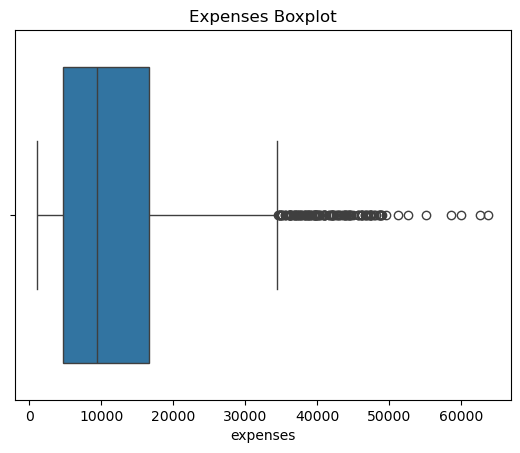

In [18]:
# Expenses
sns.boxplot(x=df['expenses'])
plt.title("Expenses Boxplot")
plt.show()

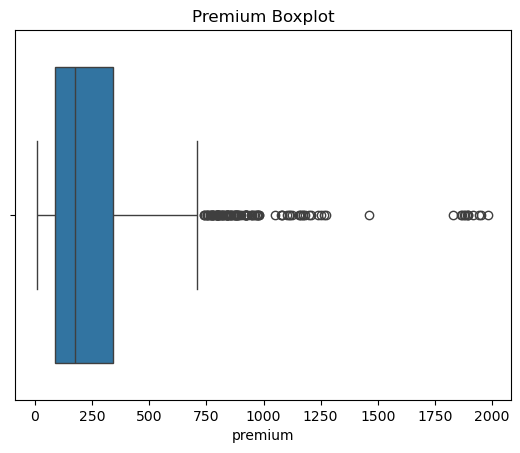

In [19]:
# Premium
sns.boxplot(x=df['premium'])
plt.title("Premium Boxplot")
plt.show()

Upon examining the boxplots for expenses and premium, we observed several extreme values, indicating the presence of outliers in the dataset. Rather than removing these outliers, we decided to retain them because they represent valid high-cost or high-premium cases, which are important for understanding the full range of insurance expenses.

To mitigate the impact of these extreme values on modeling, we applied a log-transformation to the target variables (expenses and premium). This transformation reduces skewness, compresses the scale of large values, and results in a more symmetric distribution. Consequently, it allows regression models to perform better while still preserving all the information in the dataset.

We also plan to redo the exploratory data analysis (EDA) on the log-transformed targets to properly understand their new distribution and correlations with other features.

Apply log-transformation to target variables

To better visualize the distribution of highly skewed target variables (expenses and premium), we applied a log-transformation. However, to make the plots interpretable and relate them back to the original values, we set the x-axis ticks to correspond to the real expense and premium amounts. This approach allows us to maintain the advantages of log-scaling (reducing skewness and highlighting patterns) while still providing meaningful numbers for interpretation.

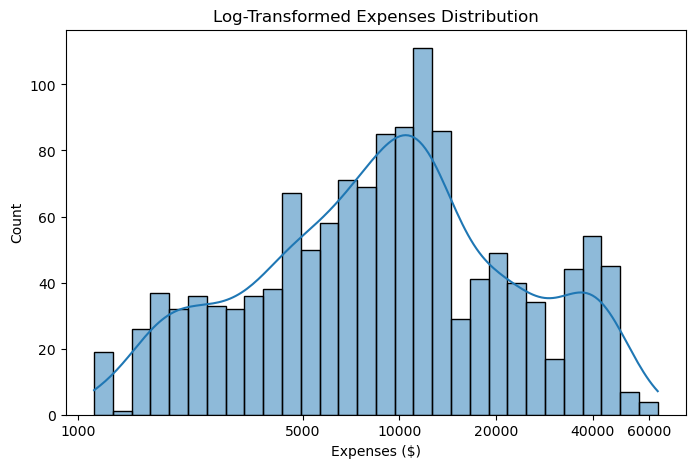

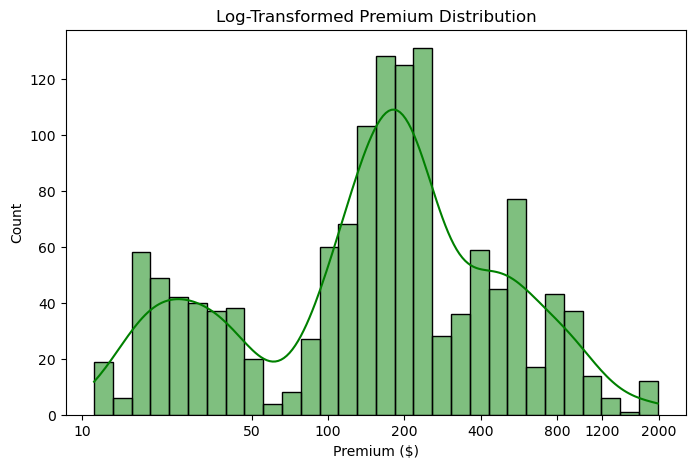

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Log-transform the target variables
df['log_expenses'] = np.log1p(df['expenses'])
df['log_premium'] = np.log1p(df['premium'])

# Plot histogram for log_expenses
plt.figure(figsize=(8,5))
sns.histplot(df['log_expenses'], bins=30, kde=True)
plt.title("Log-Transformed Expenses Distribution")

# Set x-ticks to show original expense values
log_ticks = [np.log1p(x) for x in [1000, 5000, 10000, 20000, 40000, 60000]]
plt.xticks(log_ticks, labels=[str(x) for x in [1000, 5000, 10000, 20000, 40000, 60000]])

plt.xlabel("Expenses ($)")
plt.ylabel("Count")
plt.show()

# Plot histogram for log_premium
plt.figure(figsize=(8,5))
sns.histplot(df['log_premium'], bins=30, kde=True, color='green')
plt.title("Log-Transformed Premium Distribution")

# Set x-ticks to show original premium values
log_ticks_premium = [np.log1p(x) for x in [10, 50, 100, 200, 400, 800, 1200, 2000]]
plt.xticks(log_ticks_premium, labels=[str(x) for x in [10, 50, 100, 200, 400, 800, 1200, 2000]])

plt.xlabel("Premium ($)")
plt.ylabel("Count")
plt.show()


After applying the log-transformation, the distribution of the target variables became more interpretable:

Expenses: The log-transformed expenses show an approximately normal distribution centered around $10,000. This indicates that, after reducing skewness, most policyholders have expenses near this value, while the extreme high or low values are less influential on the overall shape.

Premium: The log-transformed premiums reveal a bimodal distribution, with one peak around 25 and another around $ 250. This suggests that there are two distinct groups of policyholders in terms of premiums charged, possibly reflecting differences in coverage, age groups, or risk factors.

Correlation with other numeric variables

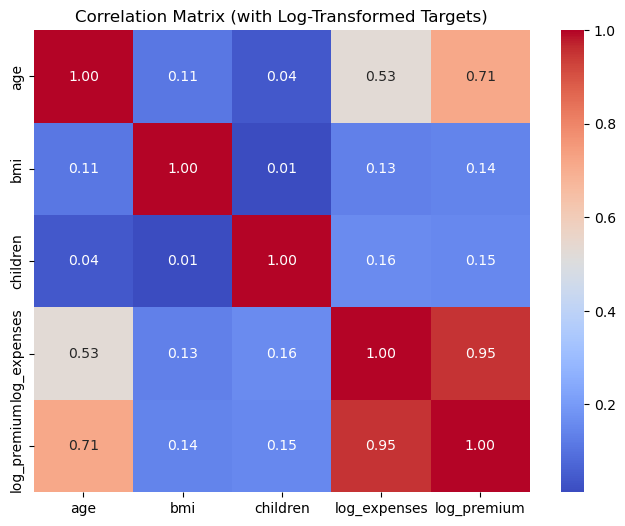

In [22]:
# Update numeric columns to include log-transformed variables
numeric_cols = ['age', 'bmi', 'children', 'log_expenses', 'log_premium']

# Correlation matrix
corr = df[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix (with Log-Transformed Targets)")
plt.show()


After applying log-transformation, the correlations between target variables and predictors became more linear and interpretable. We observed that log-expenses and log-premium are almost perfectly correlated (0.95), indicating a very close relationship between these two measures. Age shows a stronger correlation with log-premium (0.71) and a moderate correlation with log-expenses (0.53), confirming that older policyholders generally face higher costs and premiums.
On the other hand, children and BMI have only weak correlations (<0.2) with both expenses and premiums, suggesting they play a smaller role in determining costs.

Boxplots across categorical variables

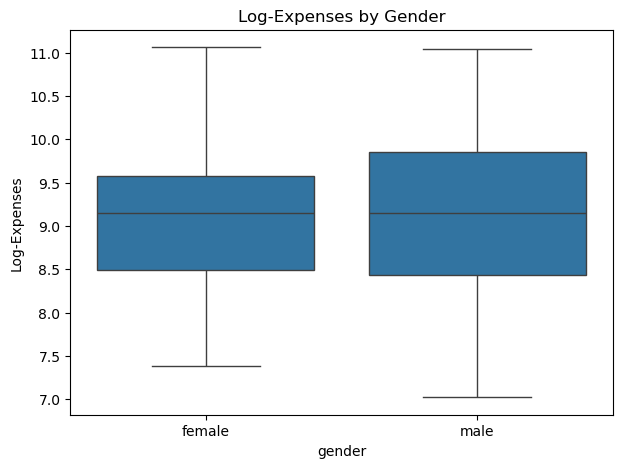

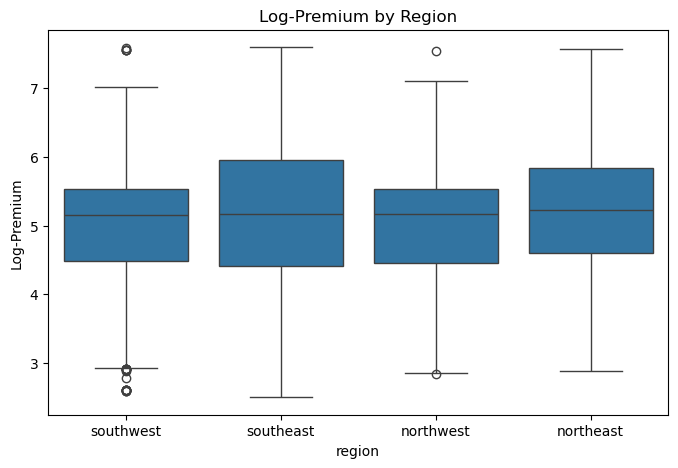

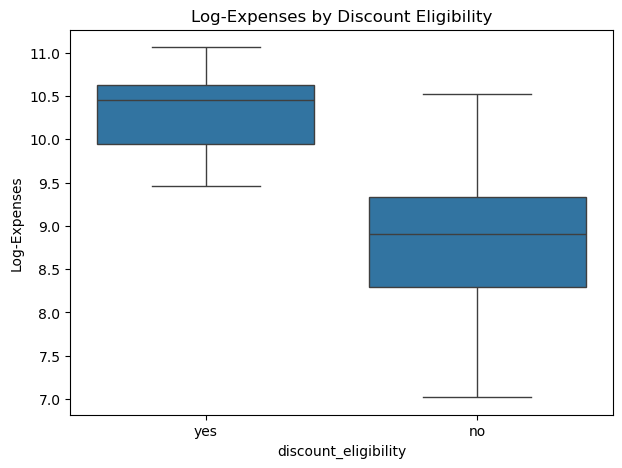

In [23]:
# Log Expenses by Gender
plt.figure(figsize=(7,5))
sns.boxplot(x='gender', y='log_expenses', data=df)
plt.title("Log-Expenses by Gender")
plt.ylabel("Log-Expenses")
plt.show()

# Log Premium by Region
plt.figure(figsize=(8,5))
sns.boxplot(x='region', y='log_premium', data=df)
plt.title("Log-Premium by Region")
plt.ylabel("Log-Premium")
plt.show()

# Log Expenses by Discount Eligibility
plt.figure(figsize=(7,5))
sns.boxplot(x='discount_eligibility', y='log_expenses', data=df)
plt.title("Log-Expenses by Discount Eligibility")
plt.ylabel("Log-Expenses")
plt.show()

Policyholders marked as discount_eligibility = yes have log-expenses ranging from 9.5 to 11, with an average around 10.5.

Policyholders marked as discount_eligibility = no have log-expenses ranging from 7 to 10.5, with an average around 8.8.

What it means in real terms:

Those eligible for a discount are actually the higher-cost policyholders.

The “discount eligibility” flag in this dataset identifies a segment of policyholders who tend to have higher insurance expenses, not that the discount reduces their expenses.

Scatterplots with continuous features

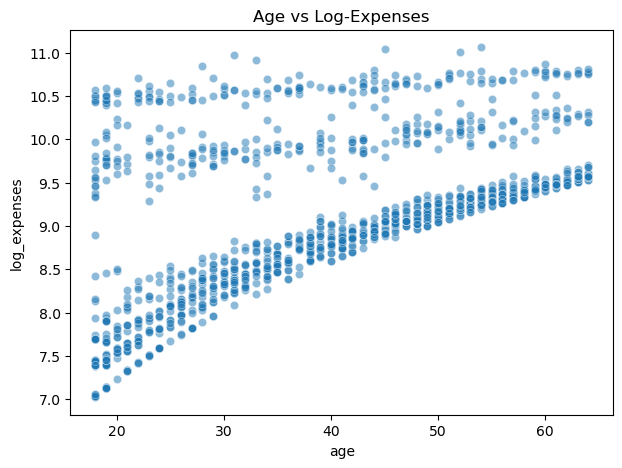

In [27]:
# Age vs Log-Expenses
plt.figure(figsize=(7,5))
sns.scatterplot(x='age', y='log_expenses', data=df, alpha=0.5)
plt.title("Age vs Log-Expenses")
plt.show()

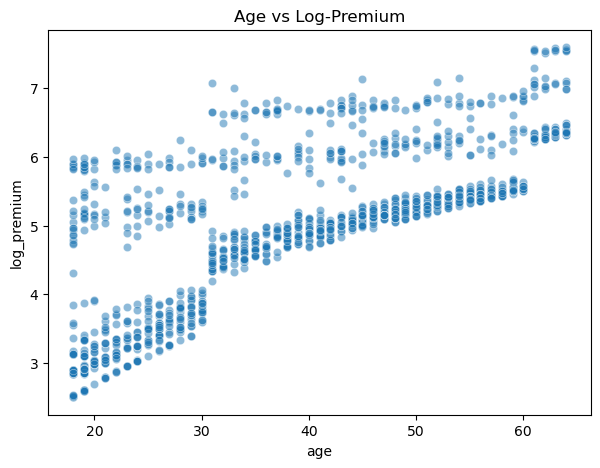

In [28]:
# Age vs Log-Premium
plt.figure(figsize=(7,5))
sns.scatterplot(x='age', y='log_premium', data=df, alpha=0.5)
plt.title("Age vs Log-Premium")
plt.show()

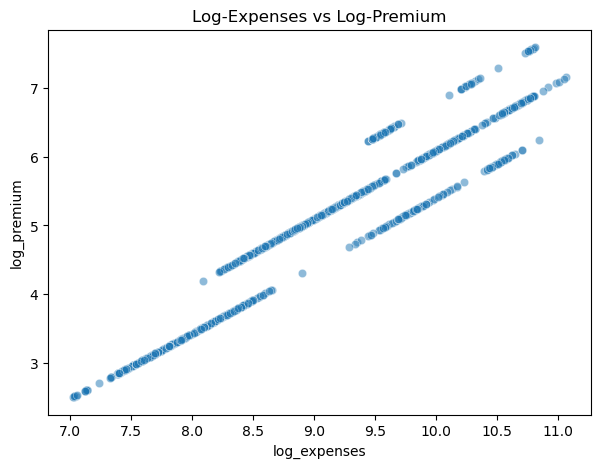

In [29]:
# Log-Expenses vs Log-Premium
plt.figure(figsize=(7,5))
sns.scatterplot(x='log_expenses', y='log_premium', data=df, alpha=0.5)
plt.title("Log-Expenses vs Log-Premium")
plt.show()

All three scatterplots — Age vs Log-Expenses, Age vs Log-Premium, and Log-Expenses vs Log-Premium — reveal clear linear relationships. This indicates that as age increases, both expenses and premiums tend to rise in a roughly linear fashion. Moreover, log-expenses and log-premium are very strongly correlated, suggesting they capture closely related aspects of policyholder costs.

Define Target

We will focus on predicting expenses, as this represents the company’s expected cost. Premiums, on the other hand, are influenced not only by statistical predictions but also by business strategy, regulations, and market competition. For instance, two companies predicting the same expected expenses may set different premiums.

Encode Categorical Features:
We need to convert categorical variables into numerical values for regression.

In [30]:
# One-hot encode categorical variables
df_encoded = pd.get_dummies(df, columns=['gender', 'discount_eligibility', 'region'], drop_first=True)

# Check first few rows
df_encoded.head()

,age,bmi,children,expenses,premium,log_expenses,log_premium,gender_male,discount_eligibility_yes,region_northwest,region_southeast,region_southwest
0,19,27.9,0,16884.92,168.8492,9.734235,5.134911,False,True,False,False,True
1,18,33.8,1,1725.55,17.2555,7.453880,2.904466,True,False,False,True,False
2,28,33.0,3,4449.46,44.4946,8.400763,3.817594,True,False,False,True,False
3,33,22.7,0,21984.47,439.6894,9.998137,6.088340,True,False,True,False,False
4,32,28.9,0,3866.86,77.3372,8.260457,4.361023,True,False,True,False,False


Define Features and Target

In [34]:
# Features (all except target columns)
X = df_encoded.drop(columns=['expenses','premium','log_expenses','log_premium'])

# Target variable
y = df_encoded['log_expenses']

# Check shapes
print(X.shape, y.shape)

(1338, 8) (1338,)


Split Data into Training and Test Sets

In [35]:
from sklearn.model_selection import train_test_split

# 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Build a Simple Regression Model (Linear Regression)

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Initialize and train model
lr = LinearRegression()
lr.fit(X_train, y_train)

# Predict
y_pred = lr.predict(X_test)

# Evaluate
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Performance:")
print("RMSE:", rmse)
print("R^2:", r2)

Linear Regression Performance:
RMSE: 0.41893906911398754
R^2: 0.8047401359736781


In [38]:
# Approximate error in original expense values
rmse_original = np.expm1(0.4189)  # inverse of log1p
print("Approximate RMSE in original $:", rmse_original)

Approximate RMSE in original $: 0.5202883183566656


Feature Importance

In [37]:
# Coefficients
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': lr.coef_}).sort_values(by='Coefficient', ascending=False)
coef_df

,Feature,Coefficient
4,discount_eligibility_yes,1.551484
2,children,0.092433
0,age,0.034238
1,bmi,0.013589
5,region_northwest,-0.056382
3,gender_male,-0.074314
7,region_southwest,-0.122475
6,region_southeast,-0.135992


Linear Regression Model on Log-Expenses

We built a linear regression model to predict log-transformed expenses (log(expenses)) using demographic and insurance-related features. This approach helps manage skewness and outliers in expense data, stabilizing variance and improving interpretability.

Key Insights from the Model

Discount Eligibility

Being eligible for a discount (discount_eligibility_yes) strongly increases predicted expenses.

On the original scale, this corresponds to a multiplicative effect of exp(1.551) ≈ 4.72× the baseline expense.

This indicates that high-cost policyholders are more likely to be in the “eligible” category.

Number of Children

Each additional child slightly increases expenses (coef ≈ 0.092), translating to ≈1.1× increase per child after exponentiation.

Age

Older policyholders have slightly higher expenses.

For every additional year, expenses increase modestly (coef ≈ 0.034, or ~3.5% per year).

BMI

Higher BMI has a small positive effect on expenses (coef ≈ 0.014).

Gender and Region

Male policyholders and those living in certain regions (southeast, southwest, northwest) have slightly lower predicted expenses compared to the baseline categories.

Model Performance

R² ≈ 0.80: The model explains ~80% of the variance in log-expenses.

RMSE ≈ 0.42: On the log scale, the prediction errors are reasonably small.

Practical Interpretation

The model helps the insurance company estimate expected costs per policyholder.

Premiums can then be set relative to predicted expenses, while taking business strategy, competition, and regulations into account.

Log-transformation ensures that extreme high-cost cases do not dominate the model and makes the multiplicative effects interpretable.